# Install Necessary Packages

In [ ]:
!pip install torch torchvision torchcam matplotlib opencv-python scikit-image pillow numpy

!pip install captum shap lime matplotlib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 4.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.0 MB/s eta 0:00:00
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=f9f6a22ef81013b88a3461de5f752a1f78aca87e52054efb0f520429b3691780
  Stored in directory: /root/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime


# Import Statements

In [ ]:
import os
import pandas as pd
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from torch.utils.data import Dataset
import numpy as np


## Safe ZIP Extraction


In [ ]:
import os
import zipfile

# Path to the zip file
zip_path = '/content/Data/glasses.zip'

# Verify the file exists
if not os.path.exists(zip_path):
    print(f"Error: File not found at {zip_path}")
    print("Please verify the file exists and the path is correct.")
else:
    # Verify the file is a zip file
    if not zipfile.is_zipfile(zip_path):
        print(f"Error: The file at {zip_path} is not a valid ZIP file")
        print("Please check if the file is corrupted or has the wrong format.")
    else:
        # Directory to extract to
        extract_path = os.path.join(os.path.dirname(zip_path), 'glasses_extracted')

        # Create extract directory if it doesn't exist
        os.makedirs(extract_path, exist_ok=True)

        try:
            # Unzip the file
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall(extract_path)

            print(f"Successfully extracted to: {extract_path}\n")

        except zipfile.BadZipFile:
            print("Error: Failed to unzip - the file appears to be corrupted")
        except Exception as e:
            print(f"An unexpected error occurred: {str(e)}")

Successfully extracted to: /content/Data/glasses_extracted



# Define paths to image folders and CSV files
pos_path: Folder containing images of people with glasses.

neg_path: Folder containing images of people without glasses.

csv_glasses: metadata for glass images.

csv_noglasses: metadata for no-glass images.

csv_glasses_file and csv_noglasses_file: Just the filenames



In [ ]:
pos_path = "/content/Data/glasses_extracted/glasses/image/pos"  # Replace with actual path
neg_path = "/content/Data/glasses_extracted/glasses/image/neg"  # Replace with actual path
csv_glasses = "/content/Data/glasses_extracted/glasses/attention_label/results_img_glasses_factual.csv"
csv_noglasses = "/content/Data/glasses_extracted/glasses/attention_label/results_img_noglasses_factual.csv"
csv_glasses_file = "results_img_glasses_factual.csv"
csv_noglasses_file = "results_img_noglasses_factual.csv"

## **Check CSV file contents**
This function loads a CSV file.

In [ ]:
def load_and_preview_csv(csv_path):
    df = pd.read_csv(csv_path)
    print(f"Preview of {csv_path}:")
    print(df.head())
    print(f"Columns: {list(df.columns)}\n")
    return df

## **Load and preview CSV files**

In [ ]:
glasses_df = load_and_preview_csv(csv_glasses)
noglasses_df = load_and_preview_csv(csv_noglasses)

Preview of /content/Data/glasses_extracted/glasses/attention_label/results_img_glasses_factual.csv:
   Unnamed: 0    img_idx                                          attention  \
0           0  04426.jpg  [[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...   
1           1  06557.jpg  [[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...   
2           2  00132.jpg  [[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...   
3           3  01210.jpg  [[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...   
4           4  05076.jpg  [[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...   

  img_check matrix_resize  
0      good    (224, 224)  
1      good    (224, 224)  
2      good    (224, 224)  
3      good    (224, 224)  
4      good    (224, 224)  
Columns: ['Unnamed: 0', 'img_idx', 'attention', 'img_check', 'matrix_resize']

Preview of /content/Data/glasses_extracted/glasses/attention_label/results_img_noglasses_factual.csv:
   Unnamed: 0    img_idx                                          attention 

# Verify image files in pos and neg directories
 confirm your dataset is clean and contains only valid image files before loading them for processing or training a model.

In [ ]:
def verify_image_files(directory):
    valid_extensions = ['.jpg', '.jpeg', '.png']
    files = [f for f in os.listdir(directory) if os.path.splitext(f)[1].lower() in valid_extensions]
    print(f"Found {len(files)} valid images in {directory}\n")
    return files

pos_files = verify_image_files(pos_path)
neg_files = verify_image_files(neg_path)

Found 1307 valid images in /content/Data/glasses_extracted/glasses/image/pos

Found 1307 valid images in /content/Data/glasses_extracted/glasses/image/neg



# **Define a transformation pipeline for images**
This transformation ensures all images are uniform in size and ready for input to a deep learning model in PyTorch.

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize all images to 224x224
    transforms.ToTensor()           # Convert PIL Image to PyTorch Tensor
])

# Visualize sample images
 visually inspect a few sample images from the dataset to verify that:

The images load correctly

The folder contains the expected content

Labels (like glasses/no-glasses) are visually valid

Sample images from 'pos' folder:


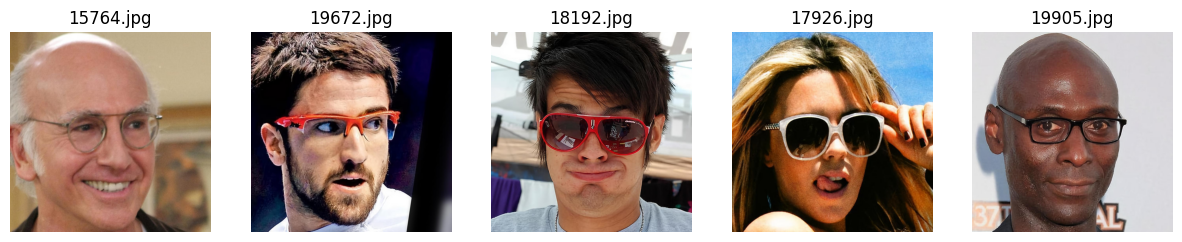

Sample images from 'neg' folder:


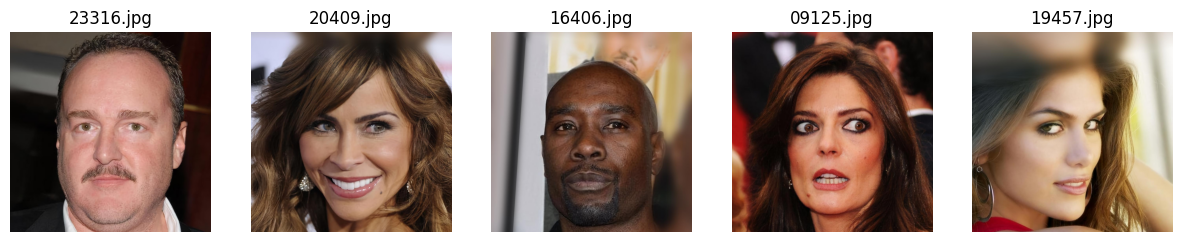

In [ ]:
def visualize_samples(files, directory, num_samples=5):
    fig, axes = plt.subplots(1, num_samples, figsize=(15, 5))
    for i, file in enumerate(files[:num_samples]):
        image = Image.open(os.path.join(directory, file)).convert("RGB")
        axes[i].imshow(image)
        axes[i].axis('off')
        axes[i].set_title(file)
    plt.show()

print("Sample images from 'pos' folder:")
visualize_samples(pos_files, pos_path)

print("Sample images from 'neg' folder:")
visualize_samples(neg_files, neg_path)

# Section 2: Combining and Labeling the Dataset

# Define a custom dataset class
This class defines a custom PyTorch dataset for a binary image classification task:

1 = person with glasses

0 = person without glasses

It prepares the dataset for loading into a model during training or testing

In [ ]:
class GlassesDataset(Dataset):
    def __init__(self, pos_files, neg_files, pos_path, neg_path, transform=None):
        self.pos_files = pos_files
        self.neg_files = neg_files
        self.pos_path = pos_path
        self.neg_path = neg_path
        self.files = self.pos_files + self.neg_files
        self.labels = [1] * len(self.pos_files) + [0] * len(self.neg_files)  # 1: glasses, 0: no glasses
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        if idx < len(self.pos_files):
            file_path = os.path.join(self.pos_path, self.files[idx])
        else:
            file_path = os.path.join(self.neg_path, self.files[idx - len(self.pos_files)])

        image = Image.open(file_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

## create dataset
This code safely prepares and loads your dataset of images for glasses vs. no-glasses classification using PyTorch.

In [ ]:
# ✅ Helper: Safely list valid image files
def get_valid_image_files(directory):
    valid_extensions = ['.jpg', '.jpeg', '.png']
    return [
        f for f in os.listdir(directory)
        if os.path.isfile(os.path.join(directory, f)) and os.path.splitext(f)[1].lower() in valid_extensions
    ]

# ✅ Refresh file lists after verifying existence
pos_files = get_valid_image_files(pos_path)
neg_files = get_valid_image_files(neg_path)

# ✅ Create the dataset using verified file lists
dataset = GlassesDataset(pos_files=pos_files, neg_files=neg_files,
                         pos_path=pos_path, neg_path=neg_path,
                         transform=transform)

# ✅ Summary printout
print("=" * 40)
print("Dataset successfully loaded:")
print(f"  Glasses images (pos):     {len(pos_files)}")
print(f" No-glasses images (neg):  {len(neg_files)}")
print(f" Total images in dataset:  {len(dataset)}")
print("=" * 40)


Dataset successfully loaded:
  Glasses images (pos):     1307
 No-glasses images (neg):  1307
 Total images in dataset:  2614


## **Visualize labeled samples**
To visually inspect a few labeled training samples and verify that:

Images are loading correctly

Labels match the expected content (e.g., glasses vs. no-glasses)

This helps confirm dataset correctness before training

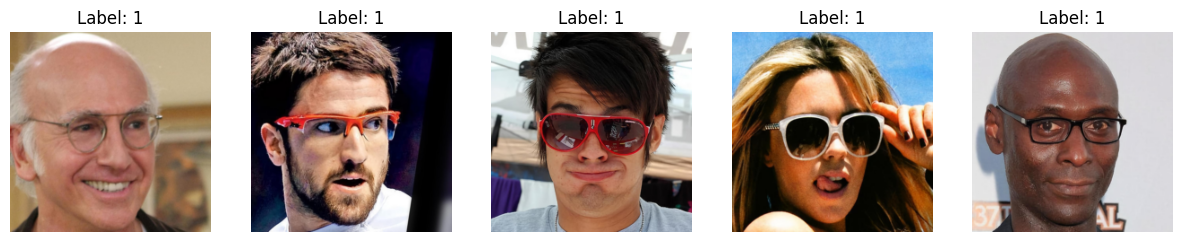

In [ ]:
#from torch.utils.data import DataLoader

def visualize_labeled_samples(dataset, num_samples=5):
    fig, axes = plt.subplots(1, num_samples, figsize=(15, 5))
    for i in range(num_samples):
        image, label = dataset[i]
        axes[i].imshow(image.permute(1, 2, 0))
        axes[i].axis('off')
        axes[i].set_title(f"Label: {label}")
    plt.show()

visualize_labeled_samples(dataset)

# Filter files
To list and count valid image files

In [ ]:
import os

def get_existing_files(directory):
    valid_exts = [".jpg", ".jpeg", ".png"]
    return sorted([
        f for f in os.listdir(directory)
        if os.path.isfile(os.path.join(directory, f)) and os.path.splitext(f)[1].lower() in valid_exts
    ])

pos_path = "/content/Data/glasses_extracted/glasses/image/pos"
neg_path = "/content/Data/glasses_extracted/glasses/image/neg"

pos_files = get_existing_files(pos_path)
neg_files = get_existing_files(neg_path)

print(f"✅ Found {len(pos_files)} valid images in pos/")
print(f"✅ Found {len(neg_files)} valid images in neg/")


✅ Found 1307 valid images in pos/
✅ Found 1307 valid images in neg/


## Define dataloader
Defines a custom PyTorch dataset class for loading images of people with and without glasses, including validation of file existence.



In [ ]:
from torch.utils.data import Dataset
from PIL import Image

class GlassesDataset(Dataset):
    def __init__(self, pos_files, neg_files, pos_path, neg_path, transform=None):
        self.images = []
        self.labels = []
        self.transform = transform

        # Add only existing files
        for f in pos_files:
            full_path = os.path.join(pos_path, f)
            if os.path.exists(full_path):
                self.images.append(full_path)
                self.labels.append(1)

        for f in neg_files:
            full_path = os.path.join(neg_path, f)
            if os.path.exists(full_path):
                self.images.append(full_path)
                self.labels.append(0)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        label = self.labels[idx]

        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label


In [ ]:
from torchvision import transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

dataset = GlassesDataset(pos_files, neg_files, pos_path, neg_path, transform=transform)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

print(f"✅ Total cleaned dataset size: {len(dataset)}")


✅ Total cleaned dataset size: 2614


# Train a model
This code fine-tunes a ResNet18 model for binary classification (glasses vs no-glasses) on our dataset using PyTorch.

In [ ]:
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet18

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load and customize ResNet18
model = resnet18(weights="DEFAULT")
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training loop
epochs = 5
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss:.4f}")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 55.2MB/s]


Epoch 1/5, Loss: 6.6333
Epoch 2/5, Loss: 1.4378
Epoch 3/5, Loss: 1.6261
Epoch 4/5, Loss: 0.6766
Epoch 5/5, Loss: 1.0711


Enables saving your trained model to disk.

Allows easy sharing.

You can reload it later

In [ ]:
torch.save(model.state_dict(), "/content/face_glass_resnet18.pth")

# LIME
To explain the prediction of your image classification model on a single image.

Shows which parts of the image influenced the model’s “glasses” prediction.

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Model loaded successfully!
True label: neg
Predicted label: neg
Probabilities: [[0.83591086 0.16408908]]


  0%|          | 0/1000 [00:00<?, ?it/s]

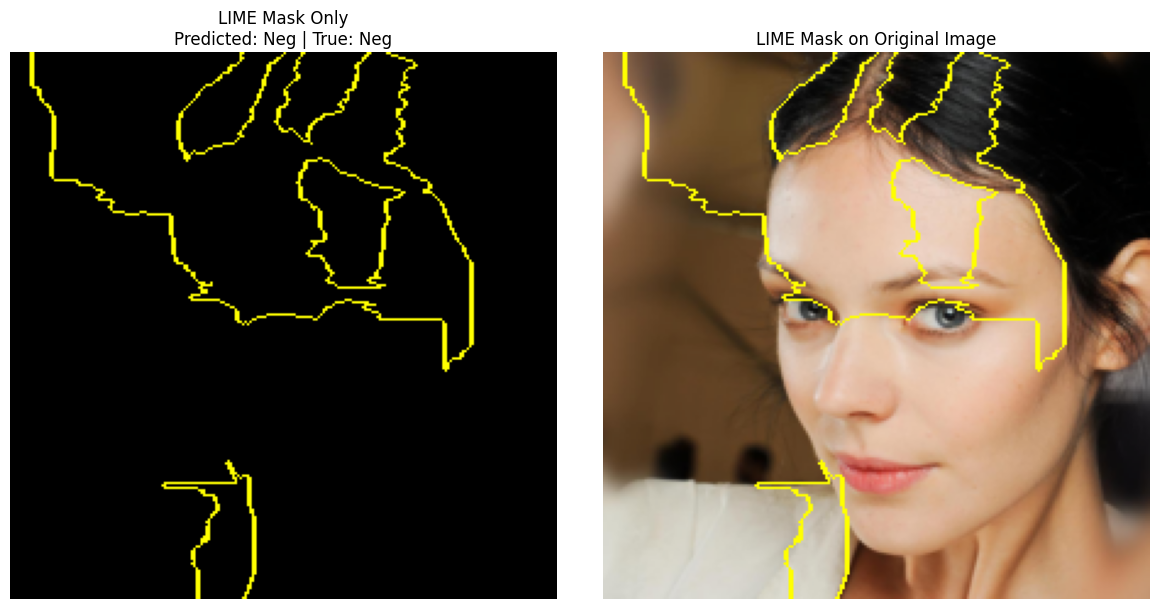

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
from torch.utils.data import DataLoader, random_split
from skimage.segmentation import mark_boundaries
from torchvision.datasets import ImageFolder
from torchvision import transforms
import torch
import torch.nn as nn
from torchvision import models

dataset_path = "/content/Data/glasses_extracted/glasses/image"

# Define your transform (with normalization)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

dataset = ImageFolder(dataset_path, transform=transform)

train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
_, test_dataset = random_split(dataset, [train_size, test_size])
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(pretrained=False)
model.fc = nn.Linear(model.fc.in_features, 2)
model_path = "/content/face_glass_resnet18.pth"
model.load_state_dict(torch.load(model_path, map_location=device))
model = model.to(device)
model.eval()
print("Model loaded successfully!")

class_names = dataset.classes

test_img, true_label_idx = next(iter(test_loader))
true_label = class_names[true_label_idx[0]]

# Inverse normalization for visualization
inv_normalize = transforms.Normalize(
    mean=[-0.485 / 0.229, -0.456 / 0.224, -0.406 / 0.225],
    std=[1 / 0.229, 1 / 0.224, 1 / 0.225]
)
input_np = inv_normalize(test_img.squeeze()).permute(1, 2, 0).cpu().numpy()
input_np = np.clip(input_np, 0, 1)

# Check model prediction on test_img
with torch.no_grad():
    outputs = model(test_img.to(device))
    probs = torch.nn.functional.softmax(outputs, dim=1)
    pred_class = probs.argmax(dim=1).item()
    predicted_label = class_names[pred_class]
    print(f"True label: {true_label}")
    print(f"Predicted label: {predicted_label}")
    print(f"Probabilities: {probs.cpu().numpy()}")

# LIME prediction function applying normalization
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225])

def predict_fn(images_np):
    model.eval()
    images_tensor = torch.tensor(images_np.transpose((0, 3, 1, 2)), dtype=torch.float32)
    for i in range(images_tensor.shape[0]):
        images_tensor[i] = normalize(images_tensor[i])
    images_tensor = images_tensor.to(device)
    outputs = model(images_tensor)
    return torch.nn.functional.softmax(outputs, dim=1).detach().cpu().numpy()

explainer = lime_image.LimeImageExplainer()
explanation = explainer.explain_instance(
    input_np,
    predict_fn,
    top_labels=2,
    hide_color=0,
    num_samples=1000
)

pred_class = explanation.top_labels[0]
lime_img, mask = explanation.get_image_and_mask(
    label=pred_class,
    positive_only=True,
    num_features=5,
    hide_rest=False
)

predicted_label = class_names[pred_class]

fig, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].imshow(mark_boundaries(lime_img / 255.0, mask))
axs[0].set_title(f"LIME Mask Only\nPredicted: {predicted_label.capitalize()} | True: {true_label.capitalize()}")
axs[0].axis('off')

axs[1].imshow(mark_boundaries(input_np, mask))
axs[1].set_title("LIME Mask on Original Image")
axs[1].axis('off')

plt.tight_layout()
plt.show()


# **Grad-CAM**
This code generates and visualizes a Grad-CAM heatmap to explain which regions of an input image influenced the model’s classification decision

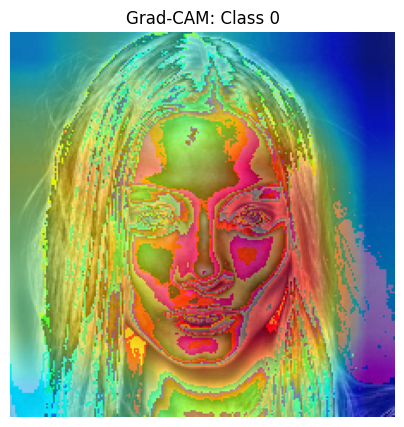

In [ ]:
from torchcam.methods import GradCAM
from torchvision.models import resnet18
import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF
import torch.nn.functional as torchF


# Load model and prepare
model = resnet18(weights="DEFAULT")
model.fc = torch.nn.Linear(model.fc.in_features, 2)
model.load_state_dict(torch.load("/content/face_glass_resnet18.pth", map_location=torch.device("cpu")))
model.eval()

# Attach Grad-CAM to last convolutional layer
cam_extractor = GradCAM(model, target_layer='layer4')

# Load one image from dataset
image_path = os.path.join(neg_path,neg_files[0])
image = Image.open(image_path).convert("RGB")
input_tensor = transform(image).unsqueeze(0)  # shape: [1, 3, 224, 224]

# Forward pass
out = model(input_tensor)
pred_class = out.argmax().item()

# Get CAM
activation_map = cam_extractor(pred_class, out)

# Overlay CAM on image
# Step 1: Convert input tensor to PIL image
input_image = TF.to_pil_image(input_tensor.squeeze(0))  # [1, 3, 224, 224] → [3, 224, 224] → PIL

# Step 2: Get and resize CAM
# Original heatmap shape: [1, 7, 7] → remove batch dimension
heatmap = activation_map[0].squeeze().detach().cpu().numpy()

# Normalize heatmap to [0, 1]
heatmap = (heatmap - np.min(heatmap)) / (np.max(heatmap) - np.min(heatmap))

# Resize heatmap to match input image size (224x224)
heatmap = Image.fromarray(np.uint8(255 * heatmap)).resize((224, 224), resample=Image.BILINEAR)
heatmap = np.array(heatmap)

# Step 3: Display the result
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(input_image)
ax.imshow(heatmap, cmap='jet', alpha=0.5)
ax.axis('off')
plt.title(f"Grad-CAM: Class {pred_class}")
plt.show()


# **SHAP**
This code uses SHAP (SHapley Additive exPlanations) with a gradient explainer to interpret which parts of an input face image influenced your ResNet18 model’s classification (glasses vs no glasses)

✅ Predicted Class: No Glasses


/tmp/ipython-input-50-3940880251.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


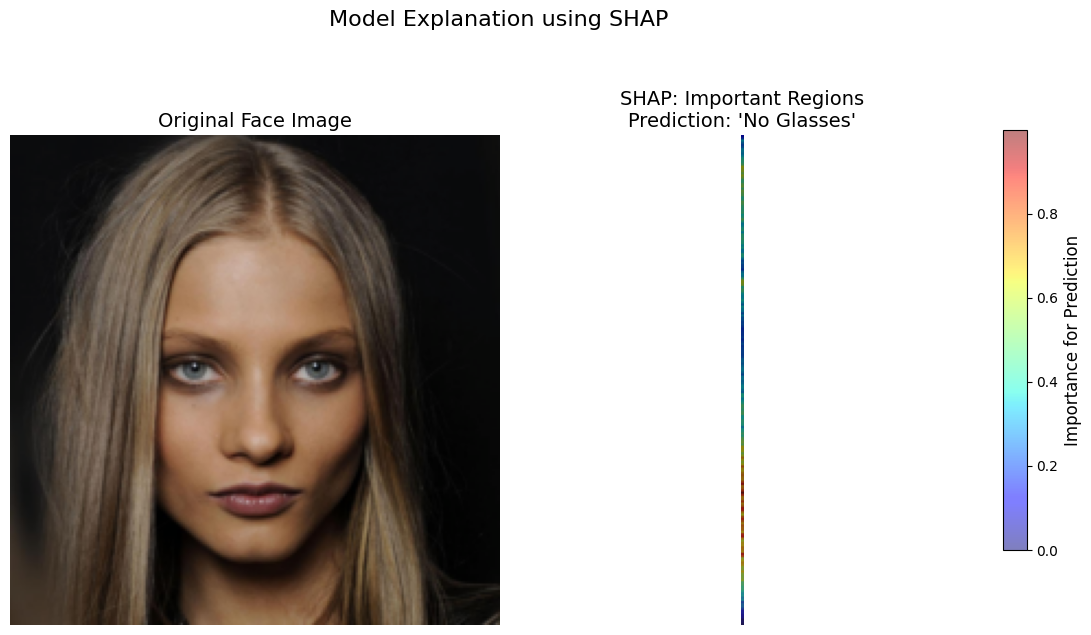

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# --- Load model for evaluation ---
model = resnet18(weights=None)  # No pretrained weights needed here
model.fc = nn.Linear(model.fc.in_features, 2)
model.load_state_dict(torch.load("/content/face_glass_resnet18.pth", map_location=device))
model = model.to(device).eval()

# Disable inplace ReLU to avoid SHAP backward issues
for module in model.modules():
    if isinstance(module, nn.ReLU):
        module.inplace = False

# --- Select some images for background dataset (e.g. first 10 samples from your dataset) ---
background_loader = DataLoader(dataset, batch_size=10, shuffle=True)
background_images, _ = next(iter(background_loader))
background_images = background_images.to(device)

# --- Choose a test image to explain (e.g., first image from dataset) ---
test_image, test_label = dataset[0]
test_image_tensor = test_image.unsqueeze(0).to(device)  # add batch dimension

# --- Create SHAP Gradient Explainer ---
explainer = shap.GradientExplainer(model, background_images)

# --- Compute SHAP values ---
shap_values, indexes = explainer.shap_values(test_image_tensor, ranked_outputs=1)

# --- Process SHAP values ---
shap_numpy = shap_values[0][0]  # First class, first example, shape: [C, H, W]
shap_gray = np.abs(shap_numpy).mean(axis=0)  # Mean absolute across channels: [H, W]
shap_scaled = (shap_gray - shap_gray.min()) / (shap_gray.max() - shap_gray.min() + 1e-8)  # Normalize

# --- Step 1: Unnormalize the image for display ---
inv_normalize = transforms.Normalize(
    mean=[-0.485 / 0.229, -0.456 / 0.224, -0.406 / 0.225],
    std=[1 / 0.229, 1 / 0.224, 1 / 0.225]
)
original_img_tensor = inv_normalize(test_image).clamp(0, 1)
original_img_np = original_img_tensor.permute(1, 2, 0).cpu().numpy()

# --- Step 2: Predict the class for label display ---
with torch.no_grad():
    outputs = model(test_image_tensor)
    predicted_class_idx = outputs.argmax(dim=1).item()
    predicted_class_name = "Glasses" if predicted_class_idx == 1 else "No Glasses"
    print(f"✅ Predicted Class: {predicted_class_name}")



# --- Step 3: Visualization ---
fig, axs = plt.subplots(1, 2, figsize=(12, 6))

# Original image
axs[0].imshow(original_img_np)
axs[0].set_title("Original Face Image", fontsize=14)
axs[0].axis('off')

# SHAP overlay
axs[1].imshow(original_img_np)
im = axs[1].imshow(shap_scaled, cmap='jet', alpha=0.5)
axs[1].set_title(f"SHAP: Important Regions\nPrediction: '{predicted_class_name}'", fontsize=14)
axs[1].axis('off')

# Colorbar
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label('Importance for Prediction', fontsize=12)

plt.suptitle("Model Explanation using SHAP", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()


## Evaluation and Analysis
This code evaluates how much the model’s confidence in its predicted class drops after masking out the important regions identified by Grad-CAM on the input image.
It validates that the Grad-CAM heatmap correctly identified regions critical for the model’s decision.
Grad-CAM:	Heatmap highlights spatial regions in the input image that most influence the model’s prediction
LIME:Highlights important superpixels that affect prediction by perturbation.
SHAP:Shows pixel-level importance values indicating contribution to prediction.


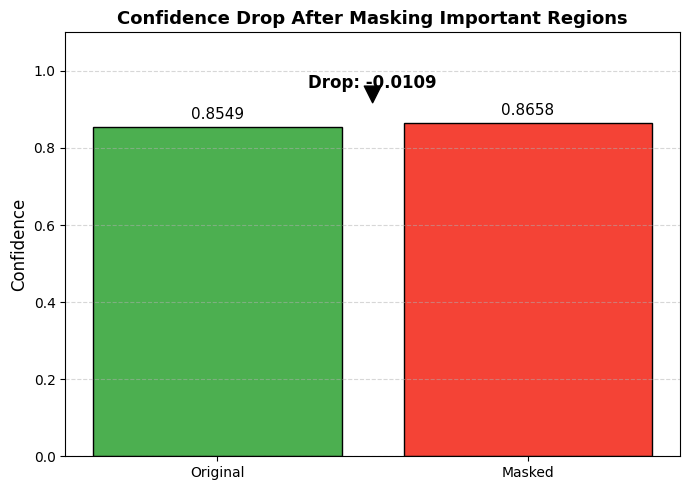

In [ ]:
from torchvision.models import resnet18
from torchcam.methods import GradCAM
import torch
import numpy as np
import matplotlib.pyplot as plt
import torchvision.transforms as transforms
from PIL import Image
import cv2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- Load model for GradCAM ---
model_cam = resnet18(weights=None)
model_cam.fc = torch.nn.Linear(model_cam.fc.in_features, 2)
model_cam.load_state_dict(torch.load("/content/face_glass_resnet18.pth", map_location=device))
model_cam = model_cam.to(device).eval()

# --- Load separate model for evaluation ---
model_eval = resnet18(weights=None)
model_eval.fc = torch.nn.Linear(model_eval.fc.in_features, 2)
model_eval.load_state_dict(torch.load("/content/face_glass_resnet18.pth", map_location=device))
model_eval = model_eval.to(device).eval()

# --- Image transform ---
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# --- Load image ---
image_path = "/content/Data/glasses_extracted/glasses/image/pos/00052.jpg"
image = Image.open(image_path).convert("RGB")
input_tensor = transform(image).unsqueeze(0).to(device)

# --- Prepare input tensor for GradCAM ---
input_tensor_cam = input_tensor.clone().detach().requires_grad_(True)

# --- GradCAM ---
cam = GradCAM(model_cam, target_layer='layer4')
output_cam = model_cam(input_tensor_cam)
predicted_class = output_cam.argmax(dim=1).item()
cam_map = cam(predicted_class, output_cam)[0].squeeze().cpu().detach().numpy()

# Normalize CAM to [0, 1]
grayscale_cam = (cam_map - cam_map.min()) / (cam_map.max() - cam_map.min() + 1e-8)

# Prepare original image numpy for masking (undo normalization)
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
img_np = input_tensor[0].cpu().permute(1, 2, 0).numpy()
img_np = std * img_np + mean
img_np = np.clip(img_np, 0, 1)

# Resize CAM heatmap to image size
grayscale_cam_resized = cv2.resize(grayscale_cam, (img_np.shape[1], img_np.shape[0]))

# Threshold top 10% important pixels
threshold = np.percentile(grayscale_cam_resized, 90)
binary_mask = grayscale_cam_resized < threshold  # Mask high importance pixels

mask_3d = np.repeat(binary_mask[:, :, np.newaxis], 3, axis=2)

masked_np = img_np.copy()
masked_np[~mask_3d] = 0

# Convert masked image back to tensor & normalize
masked_tensor = torch.tensor(masked_np.transpose(2, 0, 1)).unsqueeze(0).float().to(device)
masked_tensor = transforms.Normalize(mean.tolist(), std.tolist())(masked_tensor.squeeze(0)).unsqueeze(0)

# --- Evaluation with separate model (no gradient needed) ---
with torch.no_grad():
    original_prob = torch.nn.functional.softmax(model_eval(input_tensor), dim=1)
    masked_prob = torch.nn.functional.softmax(model_eval(masked_tensor), dim=1)

original_conf = original_prob[0, predicted_class].item()
masked_conf = masked_prob[0, predicted_class].item()
drop = original_conf - masked_conf

# --- Plot confidence drop ---
labels = ["Original", "Masked"]
confidences = [original_conf, masked_conf]
colors = ['#4CAF50', '#F44336']

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, confidences, color=colors, edgecolor='black')
plt.title("Confidence Drop After Masking Important Regions", fontsize=13, fontweight='bold')
plt.ylabel("Confidence", fontsize=12)
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.4f}', ha='center', fontsize=11)

plt.annotate(
    f"Drop: {drop:.4f}",
    xy=(0.5, masked_conf + 0.05),
    xytext=(0.5, original_conf + 0.1),
    arrowprops=dict(facecolor='black', shrink=0.05),
    ha='center',
    fontsize=12,
    fontweight='bold'
)

plt.tight_layout()
plt.show()
